# Kalman and particle filtering of the quadruple-tank process

This notebook produces every figure and table used in the report (`report.tex`).

* **Input:** `fourtank_data.mat`, the dataset from Q-1 (10,000 samples at dt = 0.1 s).
* **Output:** every figure is saved to `figures/` as both `.pdf` (used by the report) and `.png`. Every table is saved to `tables/` as a LaTeX `tabular`, which the report pulls in with `\input`. Re-running the notebook therefore updates the report automatically.

Sections follow the report: (1) system dynamics, (2) data, (3) Kalman filter, (4) tuning, (5) particle filter.

In [1]:
import os, time
import numpy as np, scipy.io as sio, matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.linalg import solve_discrete_are
from scipy.stats import norm

os.makedirs('figures', exist_ok=True); os.makedirs('tables', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 9, 'axes.titlesize': 9.5,
                     'axes.labelsize': 9, 'legend.fontsize': 7.5, 'axes.grid': True, 'grid.alpha': 0.3,
                     'lines.linewidth': 1.0, 'figure.constrained_layout.use': True})
COL = dict(true='black', meas='0.72', kf='tab:orange', pf='tab:blue', band='tab:red')

def save(fig, name):
    fig.savefig(f'figures/{name}.pdf', bbox_inches='tight'); fig.savefig(f'figures/{name}.png', bbox_inches='tight')
    plt.show()

def write_table(name, header, rows, colspec=None):
    colspec = colspec or 'l' + 'r'*(len(header) - 1)
    lines = [r'\begin{tabular}{' + colspec + '}', r'\toprule', ' & '.join(header) + r' \\', r'\midrule']
    lines += [' & '.join(r) + r' \\' for r in rows] + [r'\bottomrule', r'\end{tabular}']
    open(f'tables/{name}.tex', 'w').write('\n'.join(lines) + '\n')

D = sio.loadmat('fourtank_data.mat', squeeze_me=True, struct_as_record=False)
t, dt, N = D['t'], float(D['dt']), int(D['N'])
X_true, Y, U, p = D['x_true'], D['y_meas'], D['u'], D['p']
Qd, R, C = D['Qd'], D['R'], D['H']
A = np.array(p.A, float); a = np.array(p.a, float); g = float(p.g)
g1, g2 = p.gamma; k1, k2 = p.k; kc = float(p.kc)
names = ['$h_1$', '$h_2$', '$h_3$', '$h_4$']
after = t >= 100                                      # steady-state window for RMSE
print(f'N = {N} samples, dt = {dt} s, inputs constant at {U[:, 0]} V')
print('Q (per step) diag =', np.diag(Qd), ' R diag =', np.diag(R))

N = 10000 samples, dt = 0.1 s, inputs constant at [3 3] V
Q (per step) diag = [0.00025 0.00025 0.00025 0.00025]  R diag = [0.0025 0.0025]


## 1. System dynamics

Non-linear model (flow balance + Torricelli outflow), its equilibrium, the linearized continuous model (Slide 3), and the forward-difference discretization F = I + A_c dt, G = B_c dt.

In [2]:
def f(X, u):
    # non-linear dynamics for one state (4,) or many states (4, M)
    X = np.maximum(X, 0); q = a.reshape(4, *([1]*(X.ndim - 1)))*np.sqrt(2*g*X)
    Ar = A.reshape(4, *([1]*(X.ndim - 1)))
    return np.stack([(-q[0] + q[2] + g1*k1*u[0])/Ar[0], (-q[1] + q[3] + g2*k2*u[1])/Ar[1],
                     (-q[2] + (1 - g2)*k2*u[1])/Ar[2], (-q[3] + (1 - g1)*k1*u[0])/Ar[3]])

u0 = U[:, 0]
h3s = ((1-g2)*k2*u0[1]/a[2])**2/(2*g); h4s = ((1-g1)*k1*u0[0]/a[3])**2/(2*g)
h1s = ((g1*k1*u0[0] + a[2]*np.sqrt(2*g*h3s))/a[0])**2/(2*g)
h2s = ((g2*k2*u0[1] + a[3]*np.sqrt(2*g*h4s))/a[1])**2/(2*g)
x0 = np.array([h1s, h2s, h3s, h4s])
T = A/a*np.sqrt(2*x0/g)
Ac = np.array([[-1/T[0], 0, A[2]/(A[0]*T[2]), 0], [0, -1/T[1], 0, A[3]/(A[1]*T[3])],
               [0, 0, -1/T[2], 0], [0, 0, 0, -1/T[3]]])
Bc = np.array([[g1*k1/A[0], 0], [0, g2*k2/A[1]], [0, (1-g2)*k2/A[2]], [(1-g1)*k1/A[3], 0]])
F, G = np.eye(4) + Ac*dt, Bc*dt
O = np.vstack([C @ np.linalg.matrix_power(F, i) for i in range(4)])
print('equilibrium x0 =', x0.round(3), 'cm');  print('time constants T =', T.round(1), 's')
print('F =\n', F.round(5));  print('observability rank =', np.linalg.matrix_rank(O))
sv = np.linalg.svd(O, compute_uv=False); print('singular values of O:', sv.round(5), ' condition number:', round(sv[0]/sv[-1], 1))
F0 = F.copy(); F0[0, 2] = F0[1, 3] = 0
print('rank without the F13, F24 coupling:', np.linalg.matrix_rank(np.vstack([C @ np.linalg.matrix_power(F0, i) for i in range(4)])))
print('check: f(x0) at equilibrium =', np.abs(f(x0, u0)).max())

equilibrium x0 = [12.263 12.783  1.634  1.409] cm
time constants T = [62.4 90.6 22.8 30.1] s
F =
 [[0.9984  0.      0.00439 0.     ]
 [0.      0.9989  0.      0.00332]
 [0.      0.      0.99561 0.     ]
 [0.      0.      0.      0.99668]]
observability rank = 4
singular values of O: [0.99836 0.99762 0.00489 0.00371]  condition number: 269.4
rank without the F13, F24 coupling: 2
check: f(x0) at equilibrium = 3.172065784643304e-17


## 2. The dataset

Generated in Q-1 by Euler–Maruyama integration of the non-linear model with Gaussian process noise (σ_w = 0.05 cm/√s → Q = σ_w² dt I) and Gaussian sensor noise (σ_v = 0.05 V → R = σ_v² I).

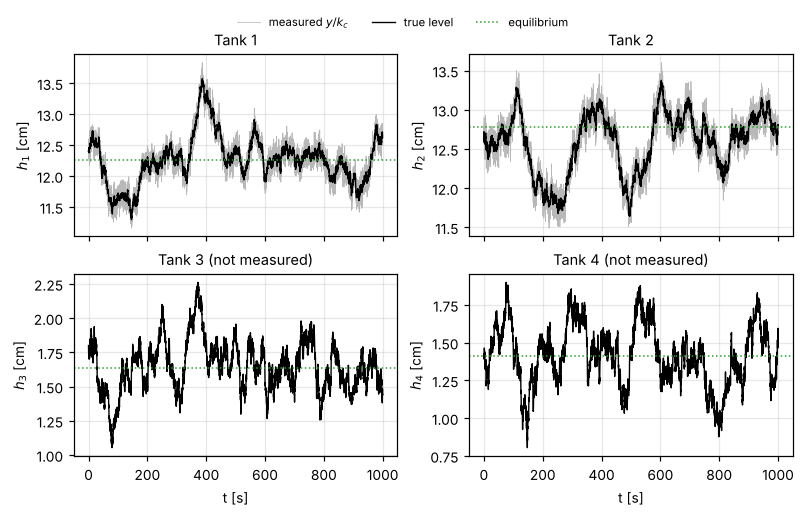

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(7.2, 4.4), sharex=True)
for i in range(4):
    A_ = ax.flat[i]
    if i < 2: A_.plot(t, Y[i]/kc, color=COL['meas'], lw=0.5, label='measured $y/k_c$')
    A_.plot(t, X_true[i], color=COL['true'], lw=0.9, label='true level')
    A_.axhline(x0[i], color='tab:green', ls=':', lw=1, label='equilibrium')
    A_.set_title(f'Tank {i+1}' + ('' if i < 2 else ' (not measured)')); A_.set_ylabel(names[i] + ' [cm]')
    if i >= 2: A_.set_xlabel('t [s]')
h_, l_ = ax[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.045), frameon=False); save(fig, 'data_overview')

## 3. Kalman filter

Linear KF on the discretized model, in deviation coordinates. The initial guess is deliberately wrong for the unmeasured tanks (ĥ₃ = 3.0, ĥ₄ = 0.5 cm; true 1.8 and 1.4) with P₀ = diag(0.01, 0.01, 1, 1) cm².

In [4]:
xh0 = np.array([Y[0, 0]/kc, Y[1, 0]/kc, 3.0, 0.5])
P0 = np.diag([R[0, 0]/kc**2, R[1, 1]/kc**2, 1.0, 1.0])

def run_kf(Qf=Qd, Rf=R):
    out = {k: np.zeros(s) for k, s in dict(xm=(4, N), xp=(4, N), Pm=(4, 4, N), Pp=(4, 4, N), K=(4, 2, N)).items()}
    for k in range(N):
        if k == 0: xm, Pm = xh0.copy(), P0.copy()
        else:
            xm = x0 + F @ (out['xp'][:, k-1] - x0) + G @ (U[:, k-1] - u0)
            Pm = F @ out['Pp'][:, :, k-1] @ F.T + Qf
        S = C @ Pm @ C.T + Rf; K = Pm @ C.T @ np.linalg.inv(S)
        xp = xm + K @ (Y[:, k] - C @ xm); IKC = np.eye(4) - K @ C
        Pp = IKC @ Pm @ IKC.T + K @ Rf @ K.T                                  # Joseph form
        out['xm'][:, k], out['xp'][:, k], out['Pm'][:, :, k], out['Pp'][:, :, k], out['K'][:, :, k] = xm, xp, Pm, Pp, K
    out['sig'] = np.sqrt(np.stack([out['Pp'][i, i] for i in range(4)]))
    out['err'] = X_true - out['xp']
    out['rmse'] = np.sqrt((out['err'][:, after]**2).mean(1))
    out['cover'] = 100*np.mean(np.abs(out['err']) <= 2*out['sig'], 1)
    return out

t0 = time.time(); kf = run_kf(); kf_time = time.time() - t0
# steady state from the discrete algebraic Riccati equation (prior covariance)
Pss_m = solve_discrete_are(F.T, C.T, Qd, R); Sss = C @ Pss_m @ C.T + R
Kss = Pss_m @ C.T @ np.linalg.inv(Sss); Pss_p = (np.eye(4) - Kss @ C) @ Pss_m
print(f'KF run time {kf_time:.2f} s')
print('max |K(end) - K_DARE| =', np.abs(kf['K'][:, :, -1] - Kss).max())
print('steady-state prior P-  diag:', np.diag(Pss_m).round(6), ' P13-:', Pss_m[0, 2].round(6))
print('steady-state post  P+  diag:', np.diag(Pss_p).round(6), ' P13+:', Pss_p[0, 2].round(6))
print('steady-state K:\n', Kss.round(4)); print('kc*K11 =', round(kc*Kss[0, 0], 4), ' K31/K11 =', round(Kss[2, 0]/Kss[0, 0], 3))
rho = lambda P: P[0, 2]/np.sqrt(P[0, 0]*P[2, 2])
print('steady-state rho13: prior', round(rho(Pss_m), 3), ' posterior', round(rho(Pss_p), 3))
print('max |P12|, |P14|, |P23|, |P34| over the run:', [np.abs(kf['Pp'][i, j]).max() for i, j in [(0, 1), (0, 3), (1, 2), (2, 3)]])
print('max |K21|, |K41|, |K12|, |K32| over the run:', [np.abs(kf['K'][i, j]).max() for i, j in [(1, 0), (3, 0), (0, 1), (2, 1)]])

KF run time 0.28 s
max |K(end) - K_DARE| = 1.6653345369377348e-15
steady-state prior P-  diag: [0.001715 0.001715 0.023924 0.031516]  P13-: 0.00069
steady-state post  P+  diag: [0.001464 0.001464 0.023883 0.031474]  P13+: 0.000589
steady-state K:
 [[0.2927 0.    ]
 [0.     0.2928]
 [0.1177 0.    ]
 [0.     0.1185]]
kc*K11 = 0.1464  K31/K11 = 0.402
steady-state rho13: prior 0.108  posterior 0.1
max |P12|, |P14|, |P23|, |P34| over the run: [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]
max |K21|, |K41|, |K12|, |K32| over the run: [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]


In [5]:
# check the element-wise covariance relations derived in the report, at a steady-state step
k = 6000; Pp_, Pm_ = kf['Pp'][:, :, k-1], kf['Pm'][:, :, k]
pred11 = F[0,0]**2*Pp_[0,0] + 2*F[0,0]*F[0,2]*Pp_[0,2] + F[0,2]**2*Pp_[2,2] + Qd[0,0]
pred13 = F[0,0]*F[2,2]*Pp_[0,2] + F[0,2]*F[2,2]*Pp_[2,2]
pred33 = F[2,2]**2*Pp_[2,2] + Qd[2,2]
S11 = kc**2*Pm_[0,0] + R[0,0]
upd = dict(P11=Pm_[0,0]*R[0,0]/S11, P13=Pm_[0,2]*R[0,0]/S11, P33=Pm_[2,2] - kc**2*Pm_[0,2]**2/S11)
print('predict:  P11', np.isclose(pred11, Pm_[0,0]), ' P13', np.isclose(pred13, Pm_[0,2]), ' P33', np.isclose(pred33, Pm_[2,2]))
print('update :  P11', np.isclose(upd['P11'], kf['Pp'][0,0,k]), ' P13', np.isclose(upd['P13'], kf['Pp'][0,2,k]), ' P33', np.isclose(upd['P33'], kf['Pp'][2,2,k]))
print(f"one update shrinks P11 by {100*(1 - R[0,0]/S11):.1f}% but P33 by only {100*kc**2*Pm_[0,2]**2/S11/Pm_[2,2]:.2f}%")

predict:  P11 True  P13 True  P33 True
update :  P11 True  P13 True  P33 True
one update shrinks P11 by 14.6% but P33 by only 0.17%


### 3.1 Prior vs posterior: the covariance ellipse expanding and contracting

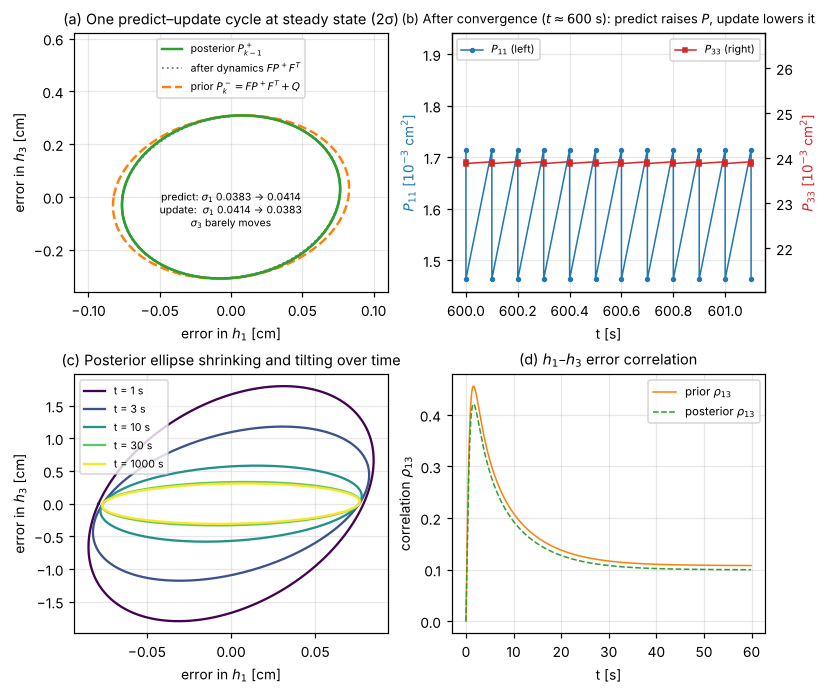

In [6]:
def ell(P2, nsig=2, n=300):
    v, V = np.linalg.eigh(P2); th = np.linspace(0, 2*np.pi, n)
    return nsig*V @ (np.sqrt(v)[:, None]*np.vstack([np.cos(th), np.sin(th)]))
i13 = np.ix_([0, 2], [0, 2])

fig, ax = plt.subplots(2, 2, figsize=(7.4, 6.2))
# (a) one predict-update cycle at steady state
A_ = ax[0, 0]; Pa = Pss_p[i13]; Pf = (F @ Pss_p @ F.T)[i13]; Pm2 = Pss_m[i13]
for P2, c, ls, lab in [(Pa, 'tab:green', '-', r'posterior $P^+_{k-1}$'), (Pf, 'tab:purple', ':', r'after dynamics $FP^+F^T$'),
                       (Pm2, 'tab:orange', '--', r'prior $P^-_k = FP^+F^T+Q$'), (Pa, 'tab:green', '-', None)]:
    e = ell(P2); A_.plot(e[0], e[1], color=c, ls=ls, lw=1.6 if ls != ':' else 1.2, label=lab)
A_.set_xlim(-0.11, 0.11); A_.set_ylim(-0.36, 0.62)
A_.set_xlabel('error in $h_1$ [cm]'); A_.set_ylabel('error in $h_3$ [cm]')
A_.set_title('(a) One predict–update cycle at steady state (2σ)'); A_.legend(loc='upper center', fontsize=6.8, ncol=1)
sp, sm = np.sqrt(Pss_p[0, 0]), np.sqrt(Pss_m[0, 0])
A_.text(0, -0.05, f'predict: $\\sigma_1$ {sp:.4f} → {sm:.4f}\nupdate:  $\\sigma_1$ {sm:.4f} → {sp:.4f}\n$\\sigma_3$ barely moves', ha='center', va='center', fontsize=6.8)
# (b) sawtooth of P11 and P33 over a few steady-state steps
A_ = ax[0, 1]; ks = np.arange(6000, 6012)
tt = np.repeat(t[ks], 2); P11 = np.ravel(np.column_stack([kf['Pm'][0, 0, ks], kf['Pp'][0, 0, ks]]))
P33 = np.ravel(np.column_stack([kf['Pm'][2, 2, ks], kf['Pp'][2, 2, ks]]))
A_.plot(tt, 1e3*P11, '-o', ms=2.5, color='tab:blue', label=r'$P_{11}$ (left)')
A_.set_ylabel(r'$P_{11}$ [$10^{-3}$ cm$^2$]', color='tab:blue'); A_.set_xlabel('t [s]')
B_ = A_.twinx(); B_.plot(tt, 1e3*P33, '-s', ms=2.5, color='tab:red', label=r'$P_{33}$ (right)'); B_.grid(False)
B_.set_ylabel(r'$P_{33}$ [$10^{-3}$ cm$^2$]', color='tab:red')
lo, hi = 1e3*P11.min(), 1e3*P11.max(); A_.set_ylim(lo - 0.1*(hi - lo), hi + 0.9*(hi - lo))
c3 = 1e3*P33.mean(); B_.set_ylim(c3*(1 - 0.12), c3*(1 + 0.12))
A_.set_title(r'(b) After convergence ($t\approx600$ s): predict raises $P$, update lowers it', fontsize=8.5); A_.legend(loc='upper left', fontsize=7); B_.legend(loc='upper right', fontsize=7)
# (c) posterior ellipse over time during the start-up transient
A_ = ax[1, 0]; cmap = plt.cm.viridis
for j, ts in enumerate([1, 3, 10, 30, 1000]):
    kk = int(round(ts/dt)) - 1; e = ell(kf['Pp'][:, :, kk][i13])
    A_.plot(e[0], e[1], color=cmap(j/4), lw=1.5, label=f't = {ts} s')
A_.set_xlabel('error in $h_1$ [cm]'); A_.set_ylabel('error in $h_3$ [cm]')
A_.set_title('(c) Posterior ellipse shrinking and tilting over time'); A_.legend(fontsize=7)
# (d) correlation and standard deviations over time
A_ = ax[1, 1]; tk = t[:600]
r_m = kf['Pm'][0, 2, :600]/np.sqrt(kf['Pm'][0, 0, :600]*kf['Pm'][2, 2, :600])
r_p = kf['Pp'][0, 2, :600]/np.sqrt(kf['Pp'][0, 0, :600]*kf['Pp'][2, 2, :600])
A_.plot(tk, r_m, color='tab:orange', label=r'prior $\rho_{13}$'); A_.plot(tk, r_p, color='tab:green', ls='--', label=r'posterior $\rho_{13}$')
A_.set_xlabel('t [s]'); A_.set_ylabel(r'correlation $\rho_{13}$'); A_.set_title(r'(d) $h_1$–$h_3$ error correlation')
A_.legend(); save(fig, 'kf_prior_posterior')

### 3.1b The staircase of P11 from an "off" initialization

P₀₁₁ is set to 1 cm² (as if the first reading had not been used). The covariance recursion uses only P₀, F, Q and R, never the measured values, so this isolates how P₁₁ converges.

P11 sequence (prior, posterior) for the first 6 steps: [1.      0.0099  0.01014 0.00503 0.00531 0.00347 0.00376 0.00273 0.00305
 0.00234 0.00267 0.00211]
posterior P11 within 25% of steady state after 9 updates (0.9 s)
posterior P11 within 10% of steady state after 43 updates (4.3 s)
posterior P11 within 1% of steady state after 169 updates (16.9 s)


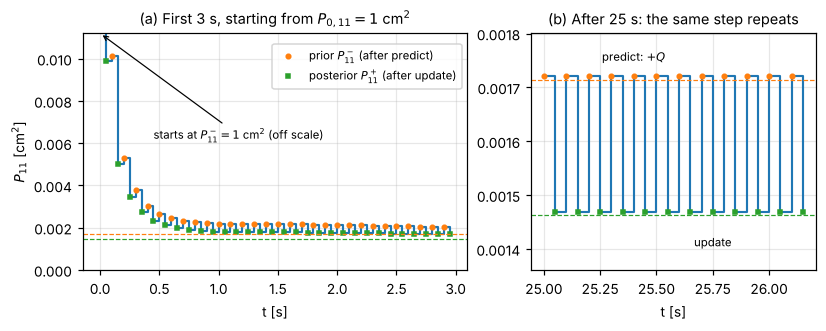

In [7]:
P0_off = P0.copy(); P0_off[0, 0] = 1.0
nst = 300; Pm11, Pp11 = np.zeros(nst), np.zeros(nst); P = P0_off.copy()
for k in range(nst):
    if k: P = F @ P @ F.T + Qd
    Pm11[k] = P[0, 0]; S = C @ P @ C.T + R; K = P @ C.T @ np.linalg.inv(S); I_ = np.eye(4) - K @ C
    P = I_ @ P @ I_.T + K @ R @ K.T; Pp11[k] = P[0, 0]
# staircase: prior at t_k, posterior half a step later; held flat until the next event
xs = np.ravel(np.column_stack([np.arange(nst)*dt, (np.arange(nst) + 0.5)*dt]))
ys = np.ravel(np.column_stack([Pm11, Pp11]))
print('P11 sequence (prior, posterior) for the first 6 steps:', np.round(ys[:12], 5))
for tol in [0.25, 0.10, 0.01]:
    k_ss = int(np.argmax(np.abs(Pp11/Pss_p[0, 0] - 1) < tol))
    print(f'posterior P11 within {100*tol:.0f}% of steady state after {k_ss} updates ({k_ss*dt:.1f} s)')

fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.9), gridspec_kw=dict(width_ratios=[1.35, 1]))
for A_, sl, log in [(ax[0], slice(0, 2*30), False), (ax[1], slice(2*250, 2*262), False)]:
    A_.step(xs[sl], ys[sl], where='post', color='tab:blue', lw=1.4)
    A_.plot(xs[sl][0::2], ys[sl][0::2], 'o', ms=3, color='tab:orange', label=r'prior $P^-_{11}$ (after predict)')
    A_.plot(xs[sl][1::2], ys[sl][1::2], 's', ms=3, color='tab:green', label=r'posterior $P^+_{11}$ (after update)')
    A_.axhline(Pss_m[0, 0], color='tab:orange', ls='--', lw=0.8); A_.axhline(Pss_p[0, 0], color='tab:green', ls='--', lw=0.8)
    A_.set_xlabel('t [s]')
    if log: A_.set_yscale('log')
ax[0].set_ylabel(r'$P_{11}$ [cm$^2$]'); ax[0].legend(loc='upper right', bbox_to_anchor=(1, 0.98)); ax[0].set_ylim(0, 0.0112)
ax[0].annotate(r'starts at $P^-_{11}=1$ cm$^2$ (off scale)', xy=(0.0, 0.0112), xytext=(0.45, 0.0062), fontsize=7.5,
               arrowprops=dict(arrowstyle='->', lw=0.8))
ax[0].set_title(r'(a) First 3 s, starting from $P_{0,11}=1$ cm$^2$')
ax[1].set_title('(b) After 25 s: the same step repeats')
ax[1].set_ylim(Pss_p[0, 0]*0.93, Pss_m[0, 0]*1.05)
ax[1].text(xs[2*254], Pss_m[0, 0]*1.02, 'predict: $+Q$', fontsize=7.5, ha='center')
ax[1].text(xs[2*257 + 1], Pss_p[0, 0]*0.96, 'update', fontsize=7.5, ha='center')
save(fig, 'kf_P_staircase')

### 3.2 Convergence of the Kalman gain, and the decoupled structure

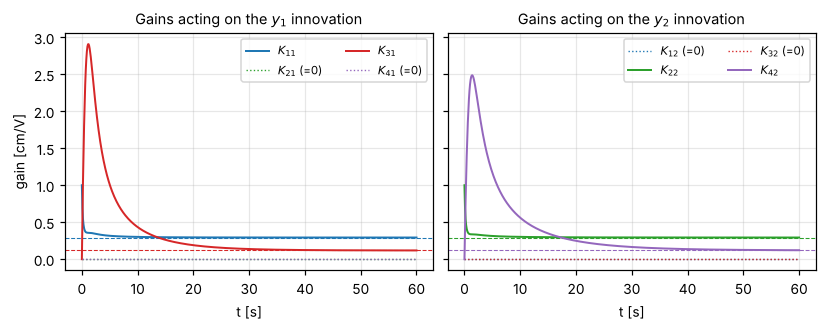

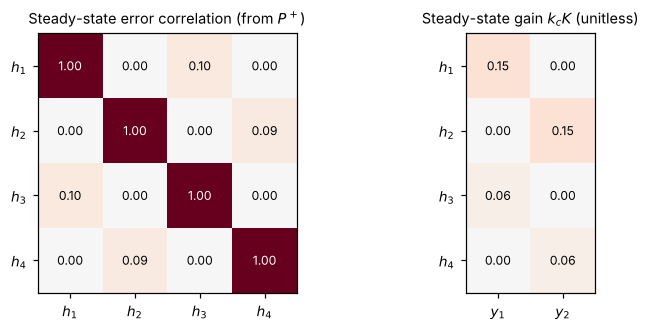

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.9), sharey=True)
cols = ['tab:blue', 'tab:green', 'tab:red', 'tab:purple']; tk = t <= 60
for j in range(2):
    for i in range(4):
        lab = f'$K_{{{i+1}{j+1}}}$' + (' (=0)' if (i % 2) != j else '')
        ax[j].plot(t[tk], kf['K'][i, j, tk], color=cols[i], lw=1.3 if (i % 2) == j else 0.9, ls='-' if (i % 2) == j else ':', label=lab)
        if (i % 2) == j: ax[j].axhline(Kss[i, j], color=cols[i], ls='--', lw=0.7)
    ax[j].set_xlabel('t [s]'); ax[j].set_title(f'Gains acting on the $y_{j+1}$ innovation'); ax[j].legend(ncol=2)
ax[0].set_ylabel('gain [cm/V]'); save(fig, 'kf_gain')

Rss = Pss_p/np.sqrt(np.outer(np.diag(Pss_p), np.diag(Pss_p)))
fig, ax = plt.subplots(1, 2, figsize=(6.6, 2.9))
for A_, M, ttl, lim in [(ax[0], Rss, 'Steady-state error correlation (from $P^+$)', 1), (ax[1], kc*Kss, r'Steady-state gain $k_c K$ (unitless)', 1)]:
    im = A_.imshow(M, cmap='RdBu_r', vmin=-lim, vmax=lim)
    for (r_, c_), v in np.ndenumerate(M): A_.text(c_, r_, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.6 else 'black')
    A_.set_yticks(range(4)); A_.set_yticklabels(names); A_.grid(False); A_.set_title(ttl)
    A_.set_xticks(range(M.shape[1])); A_.set_xticklabels(names if M.shape[1] == 4 else ['$y_1$', '$y_2$'])
save(fig, 'kf_structure')

### 3.3 Filtered estimates vs measured and true values

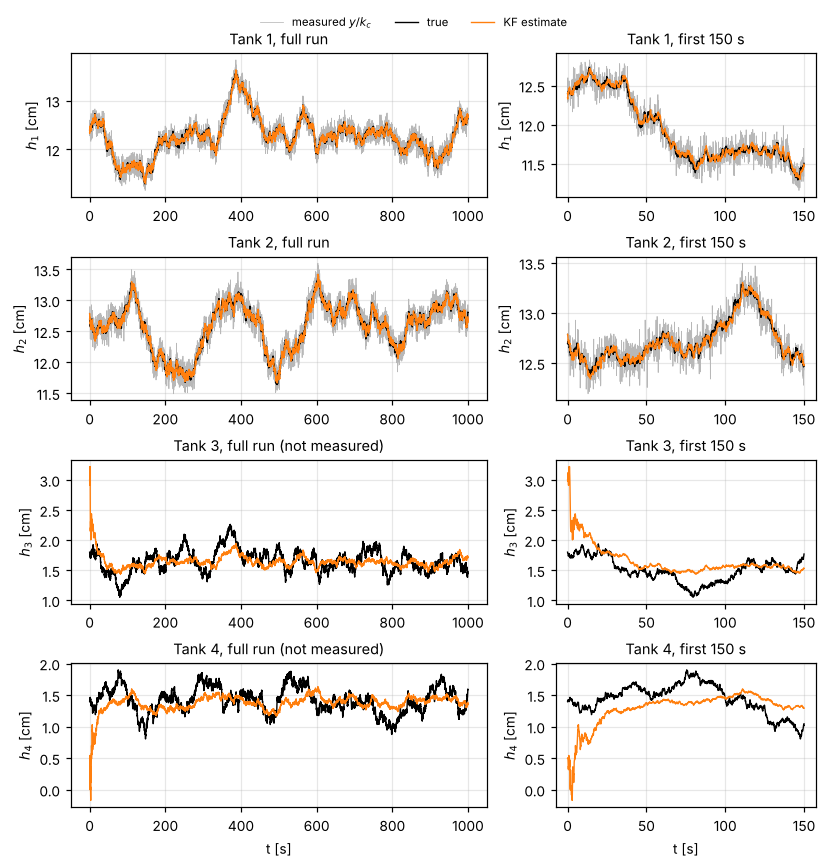

RMSE after 100 s, raw sensor: [0.1   0.101]   KF: [0.038 0.039 0.156 0.184]


In [9]:
fig, ax = plt.subplots(4, 2, figsize=(7.4, 7.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
for i in range(4):
    for j, sl in enumerate([slice(None), t <= 150]):
        A_ = ax[i, j]
        if i < 2: A_.plot(t[sl], Y[i, sl]/kc, color=COL['meas'], lw=0.5, label='measured $y/k_c$')
        A_.plot(t[sl], X_true[i, sl], color=COL['true'], lw=0.9, label='true')
        A_.plot(t[sl], kf['xp'][i, sl], color=COL['kf'], lw=0.9, label='KF estimate')
        A_.set_ylabel(names[i] + ' [cm]')
        if i == 3: A_.set_xlabel('t [s]')
    ax[i, 0].set_title(f'Tank {i+1}, full run' + ('' if i < 2 else ' (not measured)'))
    ax[i, 1].set_title(f'Tank {i+1}, first 150 s')
h_, l_ = ax[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.025), frameon=False); save(fig, 'kf_estimates')

rmse_meas = np.sqrt(((Y/kc - X_true[:2])[:, after]**2).mean(1))
print('RMSE after 100 s, raw sensor:', rmse_meas.round(3), '  KF:', kf['rmse'].round(3))

### 3.4 Validation: error inside the ±2σ band

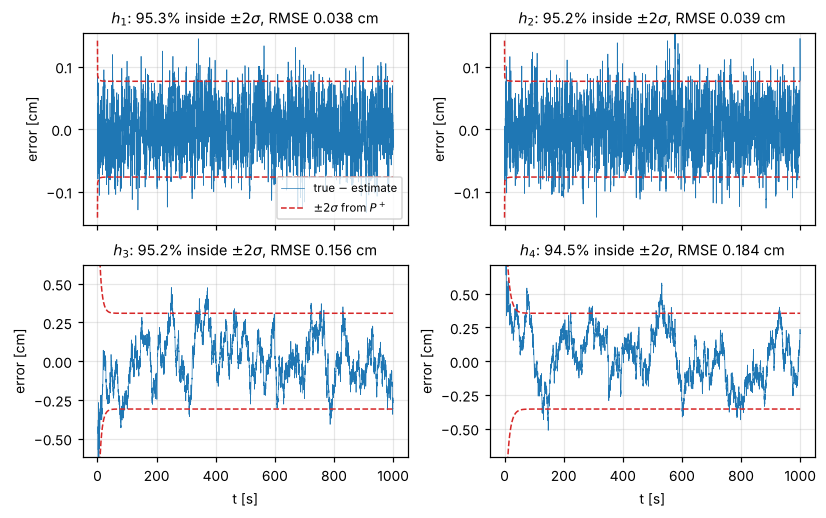

coverage: [95.4 95.2 95.2 94.4]  theoretical for a Gaussian: 95.45%


In [10]:
fig, ax = plt.subplots(2, 2, figsize=(7.4, 4.6), sharex=True)
for i in range(4):
    A_ = ax.flat[i]
    A_.plot(t, kf['err'][i], color='tab:blue', lw=0.45, label=r'true $-$ estimate')
    A_.plot(t, 2*kf['sig'][i], color=COL['band'], ls='--', lw=1); A_.plot(t, -2*kf['sig'][i], color=COL['band'], ls='--', lw=1, label=r'$\pm 2\sigma$ from $P^+$')
    A_.set_title(f'{names[i]}: {kf["cover"][i]:.1f}% inside $\\pm2\\sigma$, RMSE {kf["rmse"][i]:.3f} cm')
    A_.set_ylabel('error [cm]'); lim = 4*kf['sig'][i, -1]; A_.set_ylim(-max(lim, 0.1), max(lim, 0.1))
    if i >= 2: A_.set_xlabel('t [s]')
ax[0, 0].legend(loc='lower right'); save(fig, 'kf_2sigma')

write_table('kf_summary', ['State', 'Raw sensor RMSE [cm]', 'KF RMSE [cm]', r'Inside $\pm2\sigma$ [\%]', r'Steady $\sigma$ [cm]'],
            [[names[i], f'{rmse_meas[i]:.3f}' if i < 2 else '--', f'{kf["rmse"][i]:.3f}', f'{kf["cover"][i]:.1f}', f'{kf["sig"][i, -1]:.3f}'] for i in range(4)])
print('coverage:', kf['cover'].round(1), ' theoretical for a Gaussian: 95.45%')

## 4. Tuning the Kalman filter

Scale one entry of the filter's Q or R at a time (the data is unchanged) and record the steady-state gains, RMSE and ±2σ coverage.

$Q_{11}\times0.01$ kcK11 0.034 K31 0.241 | RMSE h1 0.059 h3 0.287 | cover h1 47% h3 54%


matched          kcK11 0.146 K31 0.118 | RMSE h1 0.038 h3 0.156 | cover h1 95% h3 95%


$Q_{11}\times100$ kcK11 0.765 K31 0.008 | RMSE h1 0.079 h3 0.173 | cover h1 97% h3 92%


$Q_{33}\times0.01$ kcK11 0.145 K31 0.001 | RMSE h1 0.039 h3 0.173 | cover h1 95% h3 18%


$Q_{33}\times100$ kcK11 0.174 K31 2.537 | RMSE h1 0.040 h3 0.494 | cover h1 97% h3 100%


$R_{11}\times0.01$ kcK11 0.766 K31 0.632 | RMSE h1 0.079 h3 0.158 | cover h1 18% h3 94%


$R_{11}\times100$ kcK11 0.016 K31 0.010 | RMSE h1 0.096 h3 0.160 | cover h1 99% h3 95%


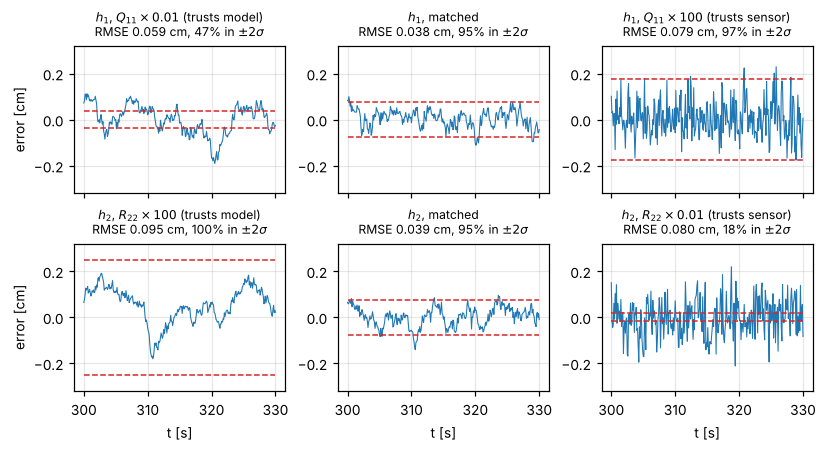

In [11]:
def scaled(M, idx, s):
    M = M.copy(); M[idx, idx] *= s; return M
cases = [('Q11', 0), ('Q33', 2), ('R11', 0)]
rows, runs = [], {}
for lab, idx in cases:
    for s in [0.01, 1, 100]:
        if lab != 'Q11' and s == 1: continue                         # matched case listed once
        Qf = scaled(Qd, idx, s) if lab[0] == 'Q' else Qd
        Rf = scaled(R, idx, s) if lab[0] == 'R' else R
        r_ = run_kf(Qf, Rf); runs[(lab, s)] = r_; K = r_['K'][:, :, -1]
        name = 'matched' if s == 1 else f'${lab[0]}_{{{lab[1:]}}}\\times{s:g}$'
        rows.append([name, f'{kc*K[0, 0]:.3f}', f'{K[2, 0]:.3f}', f'{r_["rmse"][0]:.3f}', f'{r_["rmse"][2]:.3f}',
                     f'{r_["cover"][0]:.0f}', f'{r_["cover"][2]:.0f}'])
        print(f'{name:16s} kcK11 {kc*K[0,0]:.3f} K31 {K[2,0]:.3f} | RMSE h1 {r_["rmse"][0]:.3f} h3 {r_["rmse"][2]:.3f} | cover h1 {r_["cover"][0]:.0f}% h3 {r_["cover"][2]:.0f}%')
write_table('tuning', ['Filter setting', r'$k_cK_{11}$', r'$K_{31}$ [cm/V]', r'RMSE $h_1$', r'RMSE $h_3$', r'$h_1$ in $\pm2\sigma$ [\%]', r'$h_3$ in $\pm2\sigma$ [\%]'], rows)

# the figure: h1 under Q11 scaling, h2 under R22 scaling
r_R22 = {s: run_kf(Qd, scaled(R, 1, s)) for s in [100, 0.01]}
fig, ax = plt.subplots(2, 3, figsize=(7.4, 4.0), sharex=True)
tk = (t >= 300) & (t <= 330)
panels = [(0, [('Q11', 0.01), ('Q11', 1), ('Q11', 100)], [r'$Q_{11}\times0.01$ (trusts model)', 'matched', r'$Q_{11}\times100$ (trusts sensor)']),
          (1, [100, 1, 0.01], [r'$R_{22}\times100$ (trusts model)', 'matched', r'$R_{22}\times0.01$ (trusts sensor)'])]
for row, keys, titles in panels:
    for j, (key, ttl) in enumerate(zip(keys, titles)):
        r_ = runs[key] if row == 0 else (runs[('Q11', 1)] if key == 1 else r_R22[key])
        i = row; A_ = ax[row, j]
        A_.plot(t[tk], r_['err'][i, tk], color='tab:blue', lw=0.7)
        A_.plot(t[tk], 2*r_['sig'][i, tk], color=COL['band'], ls='--'); A_.plot(t[tk], -2*r_['sig'][i, tk], color=COL['band'], ls='--')
        A_.set_ylim(-0.32, 0.32); A_.set_title(f'{names[i]}, {ttl}\nRMSE {r_["rmse"][i]:.3f} cm, {r_["cover"][i]:.0f}% in $\\pm2\\sigma$', fontsize=8)
        if j == 0: A_.set_ylabel('error [cm]')
        if row == 1: A_.set_xlabel('t [s]')
save(fig, 'tuning_2sigma')

## 5. Particle filter

Bootstrap (SIR) particle filter on the **non-linear** model: predict each particle with its own process-noise sample, weight by the Gaussian measurement likelihood (in logs), estimate by the weighted mean, and resample systematically when N_eff < N/2.

In [12]:
def systematic_resample(w, rng):
    edges = np.cumsum(w); edges[-1] = 1.0
    return np.searchsorted(edges, (rng.random() + np.arange(len(w)))/len(w))

def run_pf(Np=2000, seed=1, frac=0.5, Qf=Qd, Rf=R, record=False, event_after=500.0):
    rng = np.random.default_rng(seed); Lq = np.linalg.cholesky(Qf); Ri = np.linalg.inv(Rf)
    X = np.maximum(xh0[:, None] + np.linalg.cholesky(P0) @ rng.standard_normal((4, Np)), 0); w = np.ones(Np)/Np
    xs, sg, ne, rs = np.zeros((4, N)), np.zeros((4, N)), np.zeros(N), np.zeros(N, bool)
    snaps, bands, event = {}, np.zeros((2, 5, N)), None; qs = np.array([0.05, 0.25, 0.5, 0.75, 0.95])
    for k in range(N):
        if k: X = np.maximum(X + dt*f(X, U[:, k-1]) + Lq @ rng.standard_normal((4, Np)), 0)
        e = Y[:, k][:, None] - C @ X
        lw = np.log(w) - 0.5*np.sum(e*(Ri @ e), 0); lw -= lw.max(); w = np.exp(lw); w /= w.sum()
        m = X @ w; xs[:, k] = m; sg[:, k] = np.sqrt(((X - m[:, None])**2) @ w)
        if record:
            if k in snap_k: snaps[k] = (X.copy(), w.copy())
            if True:
                for j, i in enumerate([2, 3]):
                    o = np.argsort(X[i]); cw = np.cumsum(w[o]); bands[j, :, k] = np.interp(qs, cw/cw[-1], X[i, o])
        ne[k] = 1/np.sum(w**2)
        if ne[k] < frac*Np:
            idx = systematic_resample(w, rng)
            if record and event is None and t[k] >= event_after: event = dict(k=k, X=X.copy(), w=w.copy(), idx=idx)
            X = X[:, idx]; w = np.ones(Np)/Np; rs[k] = True
    err = X_true - xs
    return dict(x=xs, sig=sg, neff=ne, res=rs, snaps=snaps, bands=bands, event=event, Np=Np, err=err,
                rmse=np.sqrt((err[:, after]**2).mean(1)), cover=100*np.mean(np.abs(err) <= 2*sg, 1))

snap_t = [0.1, 2, 10, 30, 100, 1000]; snap_k = [int(round(s/dt)) - 1 for s in snap_t]
t0 = time.time(); pf = run_pf(2000, record=True); pf_time = time.time() - t0
print(f'PF (2000 particles): {pf_time:.1f} s, resampled on {100*pf["res"].mean():.1f}% of steps, mean N_eff {pf["neff"].mean():.0f}')
print('RMSE after 100 s  PF:', pf['rmse'].round(3), '  KF:', kf['rmse'].round(3))
print('inside 2 sigma    PF:', pf['cover'].round(1), '  KF:', kf['cover'].round(1))

PF (2000 particles): 4.5 s, resampled on 25.0% of steps, mean N_eff 1269
RMSE after 100 s  PF: [0.038 0.04  0.157 0.197]   KF: [0.038 0.039 0.156 0.184]
inside 2 sigma    PF: [95.3 95.  92.5 86.5]   KF: [95.4 95.2 95.2 94.4]


### 5.1 Estimates and the particle cloud

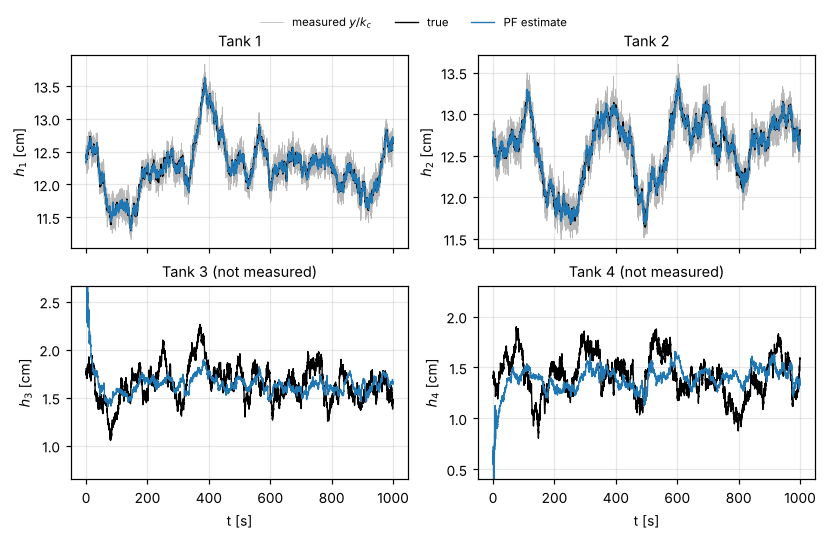

$h_3$: truth inside 90% band 86.3%, inside 50% band 45.5% (t >= 100 s)
$h_4$: truth inside 90% band 82.1%, inside 50% band 40.1% (t >= 100 s)


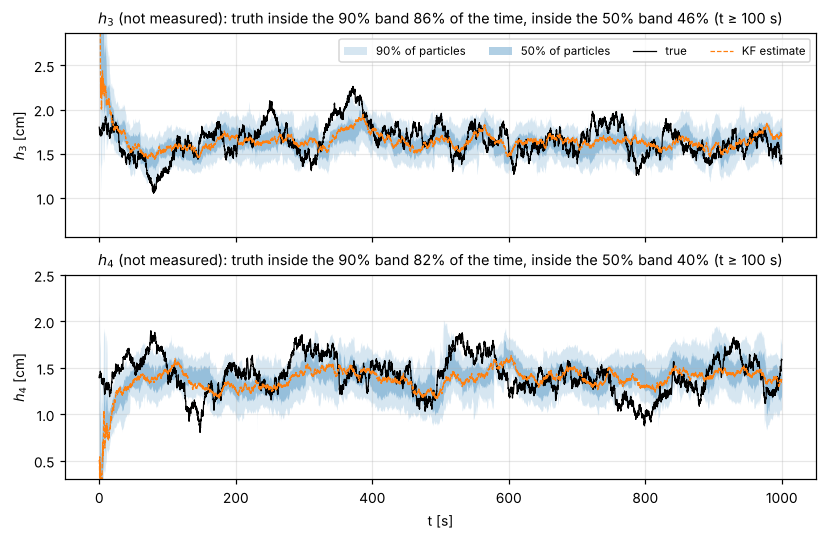

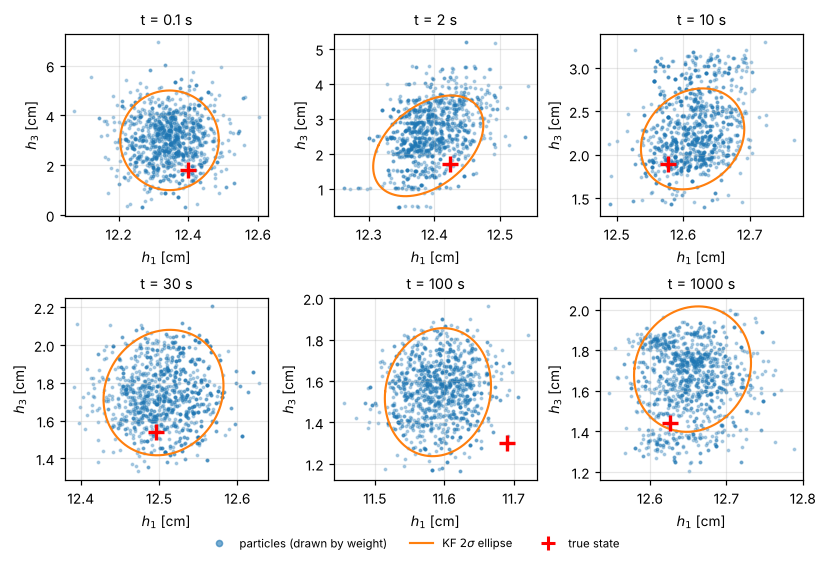

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(7.4, 4.6), sharex=True)
for i in range(4):
    A_ = ax.flat[i]
    if i < 2: A_.plot(t, Y[i]/kc, color=COL['meas'], lw=0.5, label='measured $y/k_c$')
    A_.plot(t, X_true[i], color=COL['true'], lw=0.9, label='true')
    A_.plot(t, pf['x'][i], color=COL['pf'], lw=0.9, label='PF estimate')
    A_.set_title(f'Tank {i+1}' + ('' if i < 2 else ' (not measured)')); A_.set_ylabel(names[i] + ' [cm]')
    if i >= 2: A_.set_xlabel('t [s]'); A_.set_ylim(X_true[i].min() - 0.4, X_true[i].max() + 0.4)
h_, l_ = ax[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.045), frameon=False); save(fig, 'pf_estimates')

fig, ax = plt.subplots(2, 1, figsize=(7.4, 4.8), sharex=True)
for j, i in enumerate([2, 3]):
    b = pf['bands'][j]
    in90 = 100*np.mean(((X_true[i] >= b[0]) & (X_true[i] <= b[4]))[after])
    in50 = 100*np.mean(((X_true[i] >= b[1]) & (X_true[i] <= b[3]))[after])
    ax[j].fill_between(t, b[0], b[4], color='tab:blue', alpha=0.18, lw=0, label='90% of particles')
    ax[j].fill_between(t, b[1], b[3], color='tab:blue', alpha=0.35, lw=0, label='50% of particles')
    ax[j].plot(t, X_true[i], color=COL['true'], lw=0.8, label='true')
    ax[j].plot(t, kf['xp'][i], color=COL['kf'], ls='--', lw=0.8, label='KF estimate')
    ax[j].set_title(f'{names[i]} (not measured): truth inside the 90% band {in90:.0f}% of the time, inside the 50% band {in50:.0f}% (t ≥ 100 s)')
    ax[j].set_ylabel(names[i] + ' [cm]'); ax[j].set_ylim(X_true[i].min() - 0.5, X_true[i].max() + 0.6)
    print(f'{names[i]}: truth inside 90% band {in90:.1f}%, inside 50% band {in50:.1f}% (t >= 100 s)')
ax[1].set_xlabel('t [s]'); ax[0].legend(ncol=4, loc='upper right'); save(fig, 'pf_cloud_bands')

rng_plot = np.random.default_rng(5)
fig, ax = plt.subplots(2, 3, figsize=(7.4, 4.8))
for s, (ts, k) in enumerate(zip(snap_t, snap_k)):
    A_ = ax.flat[s]; Xs, ws = pf['snaps'][k]; pick = rng_plot.choice(Xs.shape[1], 1200, p=ws)
    A_.scatter(Xs[0, pick], Xs[2, pick], s=2.5, alpha=0.3, color=COL['pf'], label='particles', rasterized=True)
    e = ell(kf['Pp'][:, :, k][i13]); A_.plot(kf['xp'][0, k] + e[0], kf['xp'][2, k] + e[1], color=COL['kf'], lw=1.4, label=r'KF $2\sigma$ ellipse')
    A_.plot(X_true[0, k], X_true[2, k], 'r+', ms=11, mew=2.2, label='true state')
    A_.set_title(f't = {ts:g} s'); A_.set_xlabel('$h_1$ [cm]'); A_.set_ylabel('$h_3$ [cm]')
from matplotlib.lines import Line2D
h_ = [Line2D([], [], ls='', marker='o', ms=4, color=COL['pf'], alpha=0.6), Line2D([], [], color=COL['kf'], lw=1.4),
      Line2D([], [], ls='', marker='+', ms=9, mew=2, color='r')]
fig.legend(h_, ['particles (drawn by weight)', r'KF $2\sigma$ ellipse', 'true state'], loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05), frameon=False)
save(fig, 'pf_snapshots')

### 5.2 Resampling, made visible

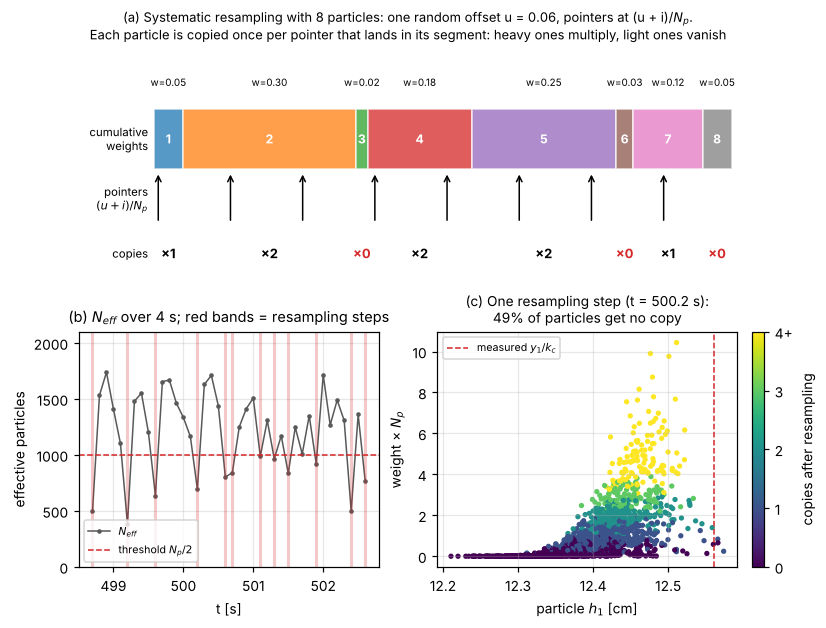

copies distribution at the event: {0: 987, 1: 530, 2: 239, 3: 118, 4: 57, 5: 34, 6: 20, 7: 8, 8: 2, 9: 2, 10: 3}


In [14]:
fig = plt.figure(figsize=(7.4, 5.6)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])
# (a) toy systematic resampling with 8 particles
A_ = fig.add_subplot(gs[0, :]); wt = np.array([0.05, 0.30, 0.02, 0.18, 0.25, 0.03, 0.12, 0.05]); Nt = len(wt)
edges = np.concatenate([[0], np.cumsum(wt)]); u_ = 0.06; ptr = (u_ + np.arange(Nt))/Nt
idx_t = np.searchsorted(np.cumsum(wt), ptr); copies = np.bincount(idx_t, minlength=Nt)
cm8 = plt.cm.tab10
for i in range(Nt):
    A_.barh(0.0, wt[i], left=edges[i], height=0.5, color=cm8(i), alpha=0.75, edgecolor='white')
    A_.text(edges[i] + wt[i]/2, 0.0, f'{i+1}', ha='center', va='center', fontsize=8, color='white', fontweight='bold')
    A_.text(edges[i] + wt[i]/2, 0.42, f'w={wt[i]:.2f}', ha='center', va='bottom', fontsize=6.5)
    A_.text(edges[i] + wt[i]/2, -0.95, f'×{copies[i]}', ha='center', va='center', fontsize=8.5,
            color='tab:red' if copies[i] == 0 else 'black', fontweight='bold')
for pp in ptr: A_.annotate('', xy=(pp, -0.27), xytext=(pp, -0.7), arrowprops=dict(arrowstyle='->', color='black', lw=1))
A_.text(-0.01, -0.5, f'pointers\n$(u+i)/N_p$', ha='right', va='center', fontsize=7.5)
A_.text(-0.01, -0.95, 'copies', ha='right', va='center', fontsize=7.5); A_.text(-0.01, 0.0, 'cumulative\nweights', ha='right', va='center', fontsize=7.5)
A_.set_xlim(-0.13, 1.01); A_.set_ylim(-1.2, 0.75); A_.axis('off')
A_.set_title(f'(a) Systematic resampling with 8 particles: one random offset u = {u_:.2f}, pointers at (u + i)/$N_p$.\n'
             'Each particle is copied once per pointer that lands in its segment: heavy ones multiply, light ones vanish', fontsize=8.5)
# (b) N_eff over a 10 s window
A_ = fig.add_subplot(gs[1, 0]); ev = pf['event']; k0 = ev['k'] - 15; win = slice(k0, k0 + 40)
A_.plot(t[win], pf['neff'][win], '-o', ms=2, color='0.35', label='$N_{eff}$')
A_.axhline(pf['Np']/2, color='tab:red', ls='--', lw=1, label='threshold $N_p/2$')
for tr in t[win][pf['res'][win]]: A_.axvline(tr, color='tab:red', alpha=0.25, lw=2)
A_.set_ylim(0, pf['Np']*1.05); A_.set_xlabel('t [s]'); A_.set_ylabel('effective particles')
A_.set_title('(b) $N_{eff}$ over 4 s; red bands = resampling steps'); A_.legend(loc='lower left', fontsize=7)
# (c) one real resampling event: weight of each particle vs its h1, coloured by number of copies
A_ = fig.add_subplot(gs[1, 1]); cp = np.bincount(ev['idx'], minlength=pf['Np'])
sc = A_.scatter(ev['X'][0], ev['w']*pf['Np'], c=np.minimum(cp, 4), cmap='viridis', s=6, vmin=0, vmax=4, rasterized=True)
A_.axvline(Y[0, ev['k']]/kc, color='tab:red', lw=1, ls='--', label='measured $y_1/k_c$')
cb = fig.colorbar(sc, ax=A_, ticks=range(5)); cb.ax.set_yticklabels(['0', '1', '2', '3', '4+']); cb.set_label('copies after resampling')
A_.set_xlabel('particle $h_1$ [cm]'); A_.set_ylabel('weight × $N_p$')
A_.set_title(f'(c) One resampling step (t = {t[ev["k"]]:.1f} s):\n{100*np.mean(cp == 0):.0f}% of particles get no copy', fontsize=9); A_.legend(loc='upper left', fontsize=7)
save(fig, 'pf_resampling')
print('copies distribution at the event:', {c: int(np.sum(cp == c)) for c in range(int(cp.max()) + 1)})

### 5.3 Validation and number of particles

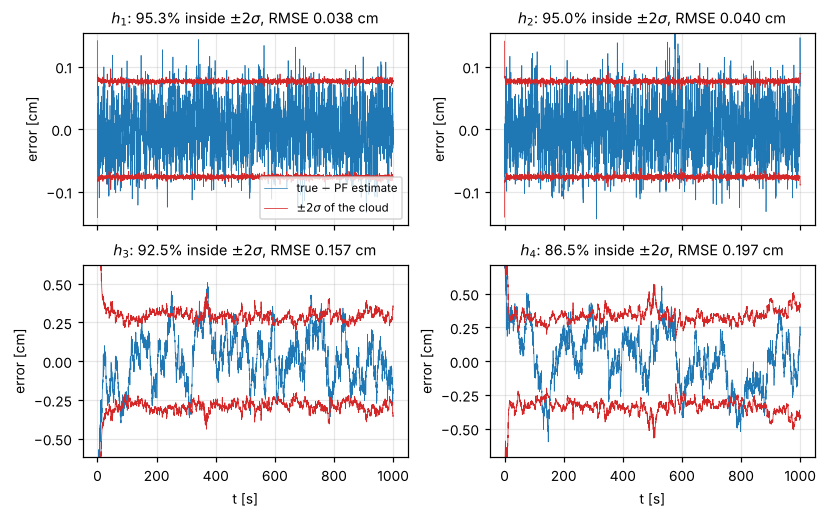

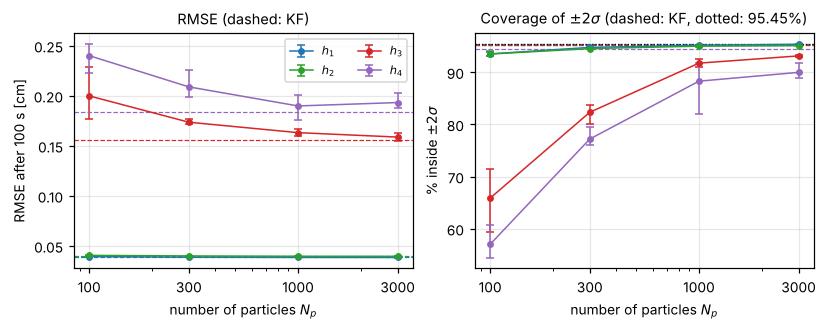

100 RMSE [0.039 0.041 0.2   0.24 ] cover [93.5 93.5 65.9 57. ] 0.7 s
300 RMSE [0.039 0.04  0.174 0.209] cover [94.8 94.5 82.3 77.2] 1.1 s
1000 RMSE [0.039 0.04  0.163 0.19 ] cover [95.2 95.  91.7 88.3] 1.8 s
3000 RMSE [0.038 0.04  0.159 0.193] cover [95.3 95.1 93.1 90. ] 4.9 s


In [15]:
fig, ax = plt.subplots(2, 2, figsize=(7.4, 4.6), sharex=True)
for i in range(4):
    A_ = ax.flat[i]
    A_.plot(t, pf['err'][i], color='tab:blue', lw=0.45, label=r'true $-$ PF estimate')
    A_.plot(t, 2*pf['sig'][i], color=COL['band'], lw=0.5); A_.plot(t, -2*pf['sig'][i], color=COL['band'], lw=0.5, label=r'$\pm2\sigma$ of the cloud')
    A_.set_title(f'{names[i]}: {pf["cover"][i]:.1f}% inside $\\pm2\\sigma$, RMSE {pf["rmse"][i]:.3f} cm')
    A_.set_ylabel('error [cm]'); lim = 4*kf['sig'][i, -1]; A_.set_ylim(-max(lim, 0.1), max(lim, 0.1))
    if i >= 2: A_.set_xlabel('t [s]')
ax[0, 0].legend(loc='lower right'); save(fig, 'pf_2sigma')

Ns, seeds = [100, 300, 1000, 3000], [1, 2, 3]; sweep = {}; times = {}
for n in Ns:
    t0 = time.time(); sweep[n] = [run_pf(n, seed=s) for s in seeds]; times[n] = (time.time() - t0)/len(seeds)
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.9)); cols = ['tab:blue', 'tab:green', 'tab:red', 'tab:purple']
for i in range(4):
    for j, key in enumerate(['rmse', 'cover']):
        v = np.array([[r_[key][i] for r_ in sweep[n]] for n in Ns]); mu = v.mean(1)
        ax[j].errorbar(Ns, mu, yerr=[mu - v.min(1), v.max(1) - mu], marker='o', ms=3.5, color=cols[i], capsize=2.5, label=names[i])
        ax[j].axhline(kf[key][i], color=cols[i], ls='--', lw=0.8)
ax[0].set_ylabel('RMSE after 100 s [cm]'); ax[1].set_ylabel(r'% inside $\pm2\sigma$'); ax[1].axhline(95.45, color='k', lw=0.8, ls=':')
for A_ in ax: A_.set_xscale('log'); A_.set_xticks(Ns); A_.set_xticklabels(Ns); A_.set_xlabel('number of particles $N_p$')
ax[0].set_title('RMSE (dashed: KF)'); ax[1].set_title(r'Coverage of $\pm2\sigma$ (dashed: KF, dotted: 95.45%)')
ax[0].legend(ncol=2); save(fig, 'pf_particles')
rows = []
for n in Ns:
    rm_ = np.mean([r_['rmse'] for r_ in sweep[n]], 0); cv_ = np.mean([r_['cover'] for r_ in sweep[n]], 0)
    rows.append([f'{n}', f'{rm_[2]:.3f}', f'{rm_[3]:.3f}', f'{cv_[2]:.1f}', f'{cv_[3]:.1f}', f'{times[n]:.1f}'])
    print(n, 'RMSE', rm_.round(3), 'cover', cv_.round(1), f'{times[n]:.1f} s')
rows.append(['KF', f'{kf["rmse"][2]:.3f}', f'{kf["rmse"][3]:.3f}', f'{kf["cover"][2]:.1f}', f'{kf["cover"][3]:.1f}', f'{kf_time:.2f}'])
write_table('pf_particles', ['Particles', r'RMSE $h_3$', r'RMSE $h_4$', r'$h_3$ in $\pm2\sigma$ [\%]', r'$h_4$ in $\pm2\sigma$ [\%]', 'Run time [s]'], rows)

### 5.4 Kalman filter vs particle filter

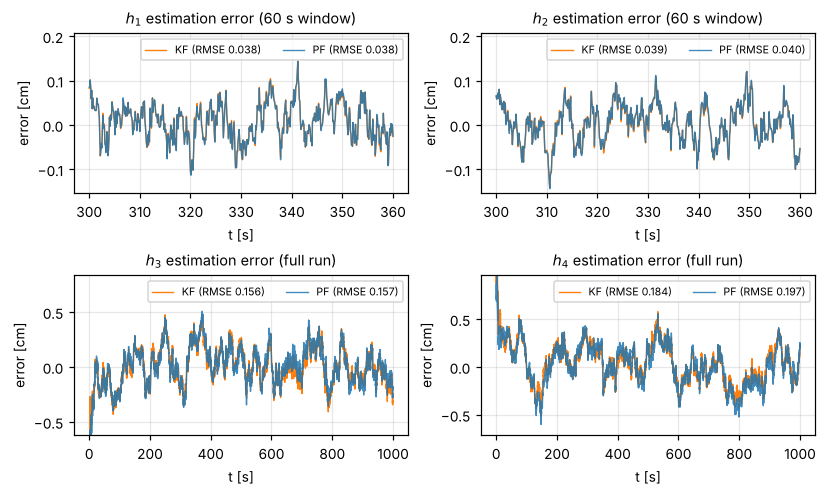

run time: KF 0.28 s, PF (2000) 4.5 s
figures: ['data_overview.pdf', 'kf_2sigma.pdf', 'kf_P_staircase.pdf', 'kf_estimates.pdf', 'kf_gain.pdf', 'kf_prior_posterior.pdf', 'kf_structure.pdf', 'kf_vs_pf.pdf', 'pf_2sigma.pdf', 'pf_cloud_bands.pdf', 'pf_estimates.pdf', 'pf_particles.pdf', 'pf_resampling.pdf', 'pf_snapshots.pdf', 'tuning_2sigma.pdf']
tables : ['kf_summary.tex', 'kf_vs_pf.tex', 'pf_particles.tex', 'tuning.tex']


In [16]:
fig, ax = plt.subplots(2, 2, figsize=(7.4, 4.4))
for i in range(4):
    A_ = ax.flat[i]; sl = (t >= 300) & (t <= 360) if i < 2 else slice(None)
    A_.plot(t[sl], kf['err'][i, sl], color=COL['kf'], lw=0.9, label=f'KF (RMSE {kf["rmse"][i]:.3f})')
    A_.plot(t[sl], pf['err'][i, sl], color=COL['pf'], lw=0.9, alpha=0.85, label=f'PF (RMSE {pf["rmse"][i]:.3f})')
    A_.set_title(f'{names[i]} estimation error' + (' (60 s window)' if i < 2 else ' (full run)')); A_.set_ylabel('error [cm]'); A_.legend(fontsize=7, ncol=2, loc='upper right')
    lim = 4*kf['sig'][i, -1]; A_.set_ylim(-max(lim, 0.1), max(lim, 0.1)*1.35)
    A_.set_xlabel('t [s]')
save(fig, 'kf_vs_pf')
write_table('kf_vs_pf', ['State', 'KF RMSE [cm]', 'PF RMSE [cm]', r'KF in $\pm2\sigma$ [\%]', r'PF in $\pm2\sigma$ [\%]'],
            [[names[i], f'{kf["rmse"][i]:.3f}', f'{pf["rmse"][i]:.3f}', f'{kf["cover"][i]:.1f}', f'{pf["cover"][i]:.1f}'] for i in range(4)])
print(f'run time: KF {kf_time:.2f} s, PF (2000) {pf_time:.1f} s')
print('figures:', sorted(f for f in os.listdir('figures') if f.endswith('.pdf')))
print('tables :', sorted(os.listdir('tables')))